# Module 2: Average Nearest-Neighbour Degree

In [45]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

In [46]:
G_chess = nx.read_gml("dataset/graph_chess.gml")

print(G_chess)
print("Directed:  ", G_chess.is_directed())
print("Multigraph:", G_chess.is_multigraph())
print("Self-loops:", nx.number_of_selfloops(G_chess))

Graph with 7115 nodes and 55779 edges
Directed:   False
Multigraph: False
Self-loops: 0


## Question 1
Plot the average nearest-neighbour degree $k_{nn}(k)$ against the degree $k$.

In [47]:
degrees = dict(G_chess.degree())               # node -> degree k_i
knn_i = nx.average_neighbor_degree(G_chess)    # node -> k_nn,i

# Check the formula by hand for one node
node = list(G_chess.nodes())[0]
neighbour_degrees = [degrees[j] for j in G_chess.neighbors(node)]

print("Node:", node)
print("Degree k_i:", degrees[node])
print("Degrees of its neighbours:", neighbour_degrees)
print("k_nn,i by hand:  ", np.mean(neighbour_degrees))
print("k_nn,i networkx: ", knn_i[node])

Node: 0
Degree k_i: 42
Degrees of its neighbours: [86, 61, 12, 17, 76, 30, 34, 70, 67, 20, 21, 45, 64, 70, 26, 31, 68, 36, 18, 43, 46, 4, 86, 63, 46, 104, 87, 26, 26, 11, 36, 71, 18, 17, 13, 30, 18, 34, 96, 20, 32, 26]
k_nn,i by hand:   42.976190476190474
k_nn,i networkx:  42.976190476190474


In [48]:
def knn_by_degree(G):
    """Compute k_nn(k). Returns two lists: the degrees k (sorted) and k_nn(k)."""
    degrees = dict(G.degree())
    knn_i = nx.average_neighbor_degree(G)

    groups = {}
    for node in G.nodes():
        k = degrees[node]
        if k not in groups:
            groups[k] = []
        groups[k].append(knn_i[node])

    ks = sorted(groups)
    knn_values = [np.mean(groups[k]) for k in ks]
    return ks, knn_values

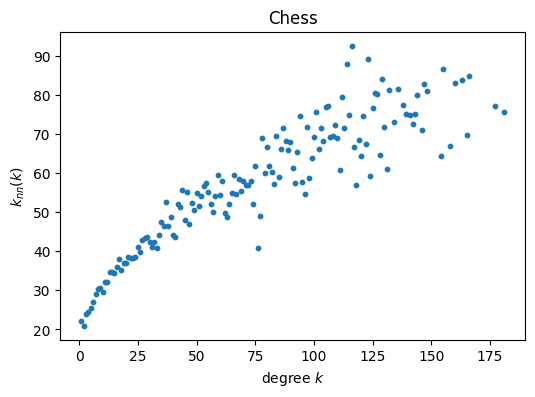

In [49]:
ks, knn_values = knn_by_degree(G_chess)

plt.figure(figsize=(6, 4))
plt.scatter(ks, knn_values, s=10)
plt.xlabel("degree $k$")
plt.ylabel("$k_{nn}(k)$")
plt.title("Chess")
plt.show()

In [50]:
def knn_by_degree(G):
    """Compute k_nn(k) for a network G.
    Returns two lists of the same length: the degrees k (sorted) and k_nn(k)."""
    degrees = dict(G.degree())
    knn_i = nx.average_neighbor_degree(G)

    groups = {}
    for node in G.nodes():
        k = degrees[node]
        if k not in groups:
            groups[k] = []
        groups[k].append(knn_i[node])

    ks = sorted(groups)
    knn_values = [np.mean(groups[k]) for k in ks]
    return ks, knn_values

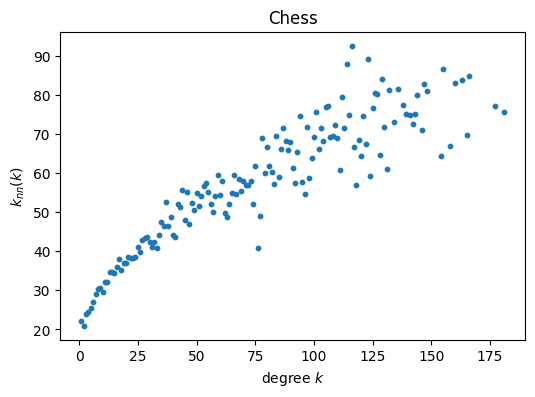

In [51]:
ks, knn_values = knn_by_degree(G_chess)

plt.figure(figsize=(6, 4))
plt.scatter(ks, knn_values, s=10)
plt.xlabel("degree $k$")
plt.ylabel("$k_{nn}(k)$")
plt.title("Chess")
plt.show()

## Question 2
Randomise the network with degree-preserving edge swaps and compare $k_{nn}(k)$.

In [52]:
G_chess_rand = nx.algorithms.smallworld.random_reference(
    G_chess.copy(), niter=2, connectivity=False, seed=42
)

# Check 1: every node still has exactly the same degree
print("Same degree for every node:", dict(G_chess.degree()) == dict(G_chess_rand.degree()))

# Check 2: same number of edges
print("Edges original:  ", G_chess.number_of_edges())
print("Edges randomised:", G_chess_rand.number_of_edges())

# Check 3: how many edges actually changed?
original_edges = {frozenset(e) for e in G_chess.edges()}
random_edges   = {frozenset(e) for e in G_chess_rand.edges()}
kept = len(original_edges & random_edges)
print("Fraction of edges still the same:", kept / len(original_edges))

Same degree for every node: True
Edges original:   55779
Edges randomised: 55779
Fraction of edges still the same: 0.04076803097940085


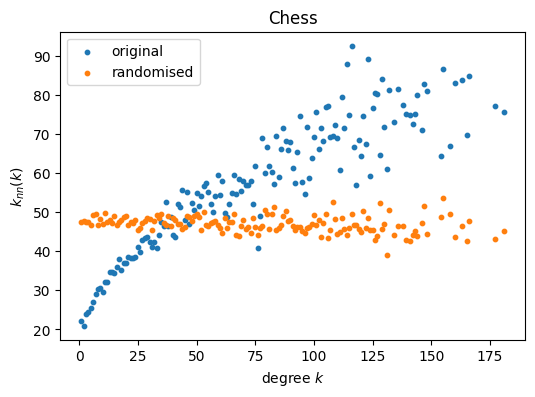

In [53]:
ks, knn_values = knn_by_degree(G_chess)
ks_r, knn_values_r = knn_by_degree(G_chess_rand)

plt.figure(figsize=(6, 4))
plt.scatter(ks, knn_values, s=10, label="original")
plt.scatter(ks_r, knn_values_r, s=10, label="randomised")
plt.xlabel("degree $k$")
plt.ylabel("$k_{nn}(k)$")
plt.title("Chess")
plt.legend()
plt.show()

## Question 3
Assortativity coefficient $r$ of the original and the randomised network.

In [54]:
r      = nx.degree_assortativity_coefficient(G_chess)
r_rand = nx.degree_assortativity_coefficient(G_chess_rand)

print("r original:  ", r)
print("r randomised:", r_rand)

r original:   0.3705153782729769
r randomised: -0.012279032588443158


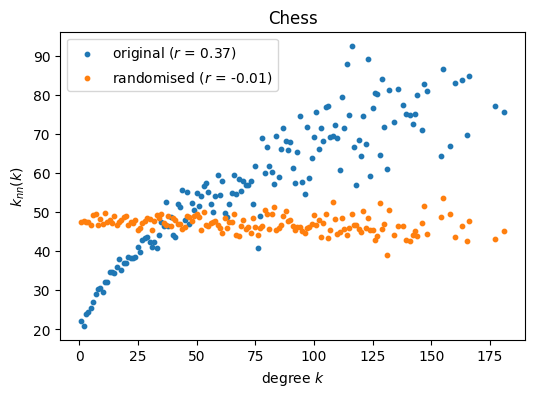

In [55]:
plt.figure(figsize=(6, 4))
plt.scatter(ks, knn_values, s=10, label=f"original ($r$ = {r:.2f})")
plt.scatter(ks_r, knn_values_r, s=10, label=f"randomised ($r$ = {r_rand:.2f})")
plt.xlabel("degree $k$")
plt.ylabel("$k_{nn}(k)$")
plt.title("Chess")
plt.legend()
plt.show()

## Question 4
Degree distribution $p(k)$ with logarithmic bins.

In [56]:
deg_list = [d for node, d in G_chess.degree()]    # one degree per node

print("Number of nodes:", len(deg_list))
print("Smallest degree:", min(deg_list))
print("Largest degree: ", max(deg_list))
print("Nodes with degree 0:", deg_list.count(0))

Number of nodes: 7115
Smallest degree: 1
Largest degree:  181
Nodes with degree 0: 0


In [57]:
k_min, k_max = min(deg_list), max(deg_list)
num_bins = 20

bins = np.logspace(np.log10(k_min), np.log10(k_max), num_bins + 1)

print("Bin edges: ", np.round(bins, 1))
print("Bin widths:", np.round(np.diff(bins), 1))

Bin edges:  [  1.    1.3   1.7   2.2   2.8   3.7   4.8   6.2   8.   10.4  13.5  17.4
  22.6  29.3  38.1  49.3  64.   83.  107.6 139.6 181. ]
Bin widths: [ 0.3  0.4  0.5  0.6  0.8  1.1  1.4  1.8  2.4  3.1  4.   5.2  6.7  8.7
 11.3 14.6 19.  24.6 31.9 41.4]


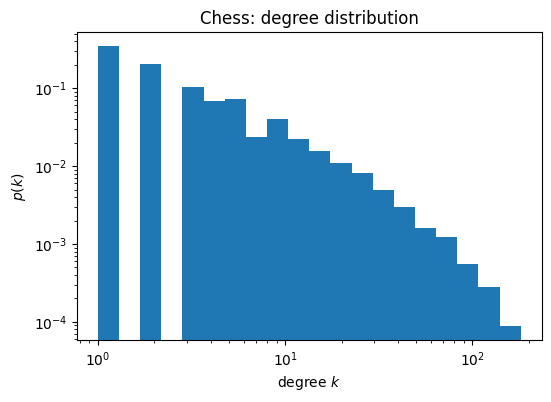

In [58]:
plt.figure(figsize=(6, 4))
plt.hist(deg_list, bins=bins, density=True)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("degree $k$")
plt.ylabel("$p(k)$")
plt.title("Chess: degree distribution")
plt.show()

In [59]:
heights, edges = np.histogram(deg_list, bins=bins, density=True)
print("Total area:", np.sum(heights * np.diff(edges)))

Total area: 1.0


## Question 5: Interpretation (Chess)

**Result: the chess network is assortative.**

1. **$k_{nn}(k)$ rises with $k$.** Players who played many games tend to play against 
   opponents who also played many games, while occasional players mostly play other 
   occasional players.

2. **The assortativity coefficient is positive:** $r \approx 0.37$. This confirms the 
   rising trend with a single number.

3. **Randomisation removes the effect.** After degree-preserving edge swaps, $k_{nn}(k)$ 
   is roughly flat and $r \approx -0.01$, i.e. close to neutral. Since the randomised 
   network has exactly the same degree distribution, the assortativity is **not** a 
   consequence of the degrees alone, but genuine structure in who plays whom 
   (e.g. strong, active players meeting at the same tournaments).

4. **Degree distribution.** Most players played only a few games, a few played very many 
   (heterogeneous $p(k)$). The randomised network has exactly the same degree distribution, 
   since edge swaps keep every node's degree, but its assortativity is almost zero. So the 
   assortativity does not come from *how many* games players play, but from *whom* they 
   play against.

This agrees with Lecture 2 (slides 45 and 58): social networks tend to be assortative.

In [60]:
def randomise(G, niter=2, seed=42):
    """Degree-preserving randomisation with edge swaps (Question 2)."""
    return nx.algorithms.smallworld.random_reference(
        G.copy(), niter=niter, connectivity=False, seed=seed
    )


def plot_knn(G, G_rand, name):
    """k_nn(k) of the original and randomised network, with r in the labels (Questions 1-3)."""
    ks, knn = knn_by_degree(G)
    ks_r, knn_r = knn_by_degree(G_rand)
    r = nx.degree_assortativity_coefficient(G)
    r_rand = nx.degree_assortativity_coefficient(G_rand)

    plt.figure(figsize=(6, 4))
    plt.scatter(ks, knn, s=10, label=f"original ($r$ = {r:.2f})")
    plt.scatter(ks_r, knn_r, s=10, label=f"randomised ($r$ = {r_rand:.2f})")
    plt.xlabel("degree $k$")
    plt.ylabel("$k_{nn}(k)$")
    plt.title(name)
    plt.legend()
    plt.show()
    return r, r_rand


def plot_degree_distribution(G, name, num_bins=20):
    """Degree distribution p(k) with logarithmic bins (Question 4)."""
    deg_list = [d for node, d in G.degree() if d > 0]
    bins = np.logspace(np.log10(min(deg_list)), np.log10(max(deg_list)), num_bins + 1)

    plt.figure(figsize=(6, 4))
    plt.hist(deg_list, bins=bins, density=True)
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("degree $k$")
    plt.ylabel("$p(k)$")
    plt.title(f"{name}: degree distribution")
    plt.show()


def analyse_network(G, name):
    """Run Questions 1-4 for one network."""
    G_rand = randomise(G)
    print("Degrees preserved:", dict(G.degree()) == dict(G_rand.degree()))

    r, r_rand = plot_knn(G, G_rand, name)
    print(f"r original: {r:.3f}   r randomised: {r_rand:.3f}")

    plot_degree_distribution(G, name)
    return G_rand

## Internet
Questions 1–4 for the Internet AS graph (nodes: autonomous systems, edges: connections between them).

In [61]:
G_int = nx.read_gml("dataset/graph_internet.gml")

print(G_int)
print("Directed:  ", G_int.is_directed())
print("Multigraph:", G_int.is_multigraph())
print("Self-loops:", nx.number_of_selfloops(G_int))

Graph with 22963 nodes and 48436 edges
Directed:   False
Multigraph: False
Self-loops: 0


Degrees preserved: True


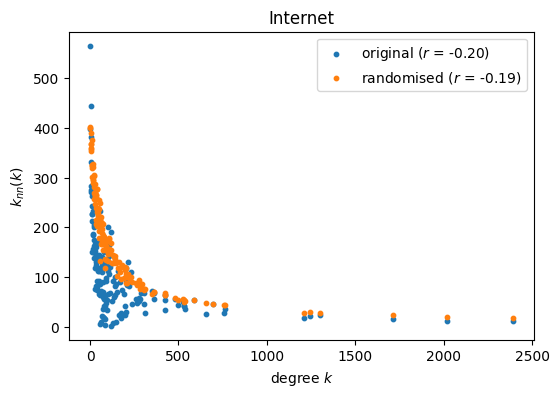

r original: -0.198   r randomised: -0.187


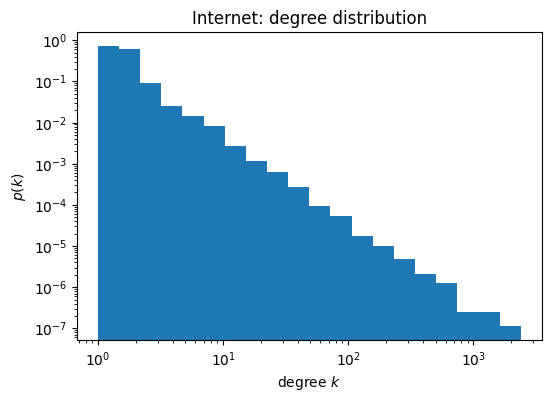

In [62]:
G_int_rand = analyse_network(G_int, "Internet")

## Question 5: Interpretation (Internet)

**Result: the Internet network is disassortative, but this is explained by its degree distribution.**

1. **$k_{nn}(k)$ falls with $k$** and $r \approx -0.2 < 0$: high-degree nodes (hubs) are mostly 
   connected to low-degree nodes.

2. **Randomisation does not change the result.** After degree-preserving edge swaps, 
   $k_{nn}(k)$ and $r$ stay almost the same ($r \approx -0.2$). By the significance test from 
   Lecture 2 (slides 50, 58), the disassortativity is therefore a consequence of the 
   degree distribution, not of a specific wiring.

3. **Degree distribution.** $p(k)$ is extremely heterogeneous: most nodes have a small degree, 
   a few hubs have degrees in the thousands. Since a hub can link to each other hub at most once 
   and there are only few hubs, most of a hub's links must go to small nodes – even in a random 
   network with the same degrees.

**Comparison with chess:** chess is assortative and the effect disappears after randomisation 
(genuine structure), whereas the Internet is disassortative and the effect survives 
randomisation (explained by the degrees). This matches Lecture 2: social networks tend to be 
assortative, technological networks disassortative.

## Summary

A reference model should keep everything except the property being tested. Here we test 
whether the *wiring* (who connects to whom) is organised.

- A **degree-preserving randomisation** keeps every node's degree, and hence the degree 
  distribution, exactly. Only the wiring is randomised, so any difference from the real 
  network can be attributed to the wiring alone.
- An **Erdős–Rényi graph** with the same number of nodes randomises the wiring *and* replaces 
  the heterogeneous degree distribution by a homogeneous one without hubs. A difference could 
  then come from either change, and we cannot tell which.

Our results show why this matters: for the Internet, the degree-preserving reference has the 
same $r \approx -0.2$, so the disassortativity is explained by the degree distribution (hubs 
must connect mostly to small nodes). An ER graph would give $r \approx 0$, and we would wrongly 
conclude that the disassortativity is genuine structure. In addition, ER has no high-degree 
nodes, so $k_{nn}(k)$ could not even be compared at large $k$.